# 8. Finite temperature

**Goal.** Compute the energy and specific heat of the TFIM at every temperature, from $T = \infty$ down to
nearly the ground state, with the same TEBD code as notebook 7 run in imaginary time. The trick is a
*purification*: a thermal density matrix written as a pure state on a chain twice as long. Every number is
checked against free fermions, $E(T) = -\sum_n \tfrac{\Lambda_n}{2}\tanh\tfrac{\Lambda_n}{2T}$.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

import dmrg_from_scratch as dmrg

RESULTS = Path("..") / "results"

## 1. A thermal state as a pure state

**Recipe.** Give every spin a partner, an *ancilla*, so each site now has dimension 4 (spin $p$ and ancilla $a$,
combined as $s = 2p + a$).

1. At $\beta = 0$ put each spin in the maximally entangled state $(|00\rangle + |11\rangle)/\sqrt2$ with its own
   ancilla. Tracing out the ancillas leaves $\rho = \mathbb 1/2^L$, the infinite-temperature state. This is a
   product state of pairs: bond dimension 1.
2. Apply $e^{-\beta H/2}$ to the spins only. Then
   $$\operatorname{Tr}_\text{anc}|\psi(\beta)\rangle\langle\psi(\beta)| \;\propto\; e^{-\beta H/2}\,\mathbb 1\,e^{-\beta H/2} = e^{-\beta H}.$$
3. Expectation values are plain MPS expectation values, $\langle O\rangle_\beta = \langle\psi(\beta)|O\otimes\mathbb
   1|\psi(\beta)\rangle/\langle\psi(\beta)|\psi(\beta)\rangle$.

(Verstraete, García-Ripoll and Cirac, [arXiv:cond-mat/0406426](https://arxiv.org/abs/cond-mat/0406426); Feiguin and
White, [arXiv:cond-mat/0510124](https://arxiv.org/abs/cond-mat/0510124).) Check it on 3 spins with dense matrices:

In [2]:
L, h, beta = 3, 1.0, 0.7
H = dmrg.mpo_to_dense(dmrg.tfim_mpo(L, h))
psi = dmrg.to_dense(dmrg.infinite_temperature_state(L)).reshape([2, 2] * L)  # (p0, a0, p1, a1, p2, a2)
psi = psi.transpose(0, 2, 4, 1, 3, 5).reshape(2**L, 2**L)  # rows: spins, columns: ancillas
E, V = np.linalg.eigh(H)
psi_beta = (V * np.exp(-beta * E / 2)) @ V.T @ psi  # e^{-beta H / 2} on the spins
rho = psi_beta @ psi_beta.conj().T
rho /= np.trace(rho)
rho_exact = (V * np.exp(-beta * E)) @ V.T
rho_exact /= np.trace(rho_exact)
print("largest difference from exp(-beta H)/Z:", np.max(np.abs(rho - rho_exact)))

largest difference from exp(-beta H)/Z: 5.551115123125783e-17


## 2. Cooling by imaginary time

Step 2 is TEBD with imaginary-time gates $e^{-\tau h_b}$ on the physical legs (identity on the ancillas). Each step
of $\tau = \delta\beta/2$ lowers the temperature by $\delta\beta$. The gates are not unitary, so the norm changes;
the truncated SVD renormalizes it at every bond, and only normalized expectation values are used. A live run, 12
spins at the critical field:

In [3]:
L, h, chi = 12, 1.0, 32
betas = np.round(np.arange(0.1, 8.001, 0.1), 6)
mpo = dmrg.purify_mpo(dmrg.tfim_mpo(L, h))
E_mps, S_mps = [], []
for beta, mps, disc in dmrg.thermal_states(L, h, betas, chi_max=chi, dbeta=0.05):
    E_mps.append(dmrg.mpo_expectation(mps, mpo))
    S_mps.append(dmrg.half_chain_entropy(mps))
E_mps = np.array(E_mps)
ex = dmrg.tfim_thermal(L, h, 1 / betas)
print(f"largest error in E/L: {np.max(np.abs(E_mps - ex['energy'])) / L:.1e}, discarded weight {disc:.0e}")
print(f"at beta = 8: E/L = {E_mps[-1] / L:.6f}, ground state {dmrg.tfim_open_energy(L, h) / L:.6f}")
print(f"gap of the 12-spin chain: {dmrg.tfim_open_gap(L, h):.3f}")

largest error in E/L: 8.0e-06, discarded weight 8e-14
at beta = 8: E/L = -1.241196, ground state -1.243831
gap of the 12-spin chain: 0.251


The error is set by the Trotter step, $\sim\delta\beta^2$, not by $\chi$. At $\beta = 8$ the energy is still about $3\times10^{-3}$ per site above the ground
state: $\beta$ times the finite-size gap (printed above) is only about 2, so the lowest excited states still
contribute. Zero temperature on a finite chain means $\beta \gg 1/\text{gap}$.

## 3. The specific heat

The specific heat is the slope of the energy, $C = dE/dT = -\beta^2\, dE/d\beta$. A finite difference on the
$\beta$ grid is enough:

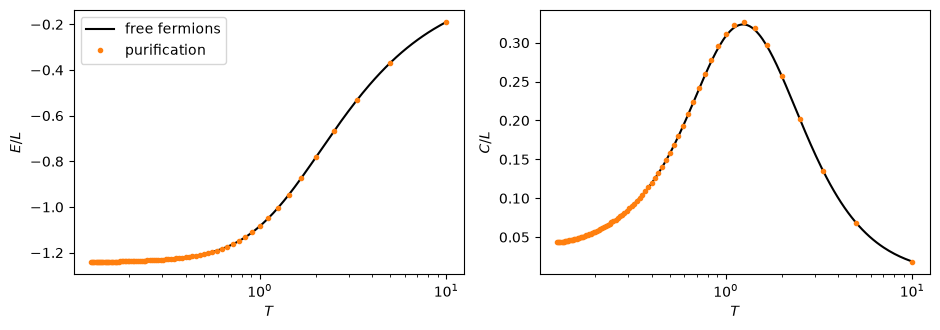

In [4]:
C_mps = -(betas**2) * np.gradient(E_mps, betas)
T = 1 / betas
T_fine = np.logspace(np.log10(T.min()), np.log10(T.max()), 200)
ex_fine = dmrg.tfim_thermal(L, h, T_fine)
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
ax[0].plot(T_fine, ex_fine["energy"] / L, "k-", label="free fermions")
ax[0].plot(T, E_mps / L, "C1o", ms=3, label="purification")
ax[0].set(xscale="log", xlabel="$T$", ylabel="$E/L$")
ax[0].legend()
ax[1].plot(T_fine, ex_fine["specific_heat"] / L, "k-")
ax[1].plot(T, C_mps / L, "C1o", ms=3)
ax[1].set(xscale="log", xlabel="$T$", ylabel="$C/L$")
fig.tight_layout()

The specific heat has a broad peak where $T$ is comparable to the single-particle energies, which at $h = J$
spread from 0 to $4J$ ($\varepsilon(q) = 2\sqrt{2 - 2\cos q}$), and it falls to zero at both ends: at high $T$ every state is equally likely already, and at low $T$ nothing can be excited.

## 4. How much entanglement does a thermal state need?

The purification starts as a product state (zero entanglement between the two halves of the doubled chain) and
ends, at $T \to 0$, as $|\psi_0\rangle\otimes|\psi_0^*\rangle$ (the ground state on the spins, its mirror image on
the ancillas), which has twice the ground-state entanglement. In between, a thermal state has correlations only
over a thermal length that shrinks as $T$ grows, so it needs much less bond dimension than the ground state at high
temperature. The full run, 32 spins at three bond dimensions, from `results/thermal.json`
(`python scripts/make_results.py thermal`, about a minute on 4 cores):

chi =  8: largest error in E/L = 2.4e-04 (at beta = 10.0)
chi = 16: largest error in E/L = 9.3e-06 (at beta = 1.4)
chi = 64: largest error in E/L = 9.3e-06 (at beta = 1.4)


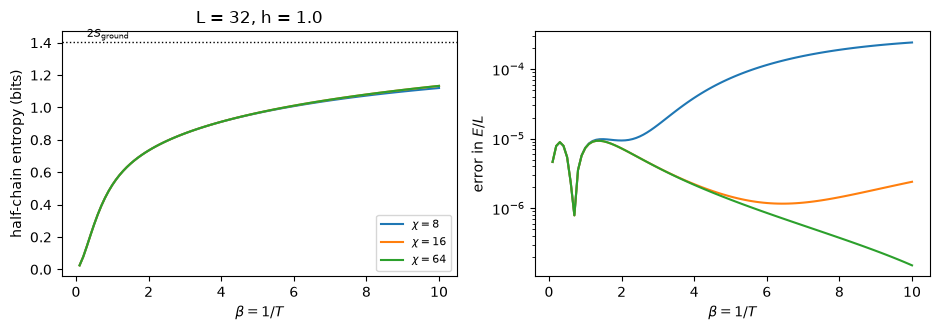

In [5]:
th = json.loads((RESULTS / "thermal.json").read_text())
Lt, ht = th["L"], th["h"]
g = dmrg.dmrg(dmrg.tfim_mpo(Lt, ht), chi_max=64, n_sweeps=4)
S0 = g["entropies"][Lt // 2 - 1]
fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
for run in th["runs"]:
    b = np.array(run["beta"])
    exr = dmrg.tfim_thermal(Lt, ht, 1 / b)
    ax[0].plot(b, run["S"], label=rf"$\chi = {run['chi']}$")
    ax[1].semilogy(b, np.abs(np.array(run["energy"]) - exr["energy"]) / Lt, label=rf"$\chi = {run['chi']}$")
ax[0].axhline(2 * S0, color="k", ls=":", lw=1)
ax[0].text(0.3, 2 * S0 + 0.03, r"$2S_\mathrm{ground}$", fontsize=8)
ax[0].set(xlabel=r"$\beta = 1/T$", ylabel="half-chain entropy (bits)", title=f"L = {Lt}, h = {ht}")
ax[1].set(xlabel=r"$\beta = 1/T$", ylabel="error in $E/L$")
ax[0].legend(fontsize=8)
fig.tight_layout()
for run in th["runs"]:
    b = np.array(run["beta"])
    err = np.abs(np.array(run["energy"]) - dmrg.tfim_thermal(Lt, ht, 1 / b)["energy"]) / Lt
    print(f"chi = {run['chi']:2d}: largest error in E/L = {err.max():.1e} (at beta = {b[err.argmax()]:.1f})")

At high temperature (small $\beta$) the entanglement is small and even $\chi = 8$ is exact to the Trotter error.
As $T$ drops the entropy climbs towards $2S_\text{ground}$ (dotted; at $\beta = 10$ it is not there yet, because the
32-spin chain at the critical field has a small gap), and $\chi = 8$ starts to fail below $T \approx 0.4$, while
$\chi = 16$ is still as good as $\chi = 64$: the low-temperature state needs the bond dimension of the ground state. The rule of thumb: finite temperature is *easier* than the ground
state for MPS, and the cost is set by how low you need to go.

A second route, METTS (minimally entangled typical thermal states), samples pure states instead of carrying the
ancillas, at a cost comparable to ground-state DMRG (White, [arXiv:0902.4475](https://arxiv.org/abs/0902.4475);
Stoudenmire and White, [arXiv:1002.1305](https://arxiv.org/abs/1002.1305)). Exercise 4 sketches it.

## Exercises

1. Halve $\delta\beta$ in Section 2 and check that the error in $E/L$ falls by about 4.
2. Compute $\langle Z_i\rangle_\beta$ with `dmrg.local_expectations`, using the operator $Z\otimes\mathbb 1$ on
   the 4-dimensional site, and compare with the derivative of the free energy,
   $\langle\sum_i Z_i\rangle = -\partial F/\partial h$ (finite difference of `dmrg.tfim_thermal(...)["free_energy"]`).
3. In the ordered phase, $h = 0.5$, how does the low-temperature entropy of the purification compare with
   $2S_\text{ground}$? (Hint: the open chain has two nearly degenerate ground states.)
4. METTS: start from a random product state in the $Z$ basis, apply $e^{-\beta H/2}$ with real-spin TEBD
   (notebook 7's code with `imaginary=True`), normalize, measure the energy, then collapse every spin to a $Z$
   eigenstate with the Born probabilities and repeat. Average the energies and compare with Section 2.